In [1]:
import os
import torch
import numpy as np
import cv2
from skimage import metrics
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import skimage.util as util
import pywt
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt


In [2]:
from PIL import Image

In [3]:
'''# Define the transformation for image preprocessing
transform = transforms.Compose([
    ,  # Convert image to grayscale (if needed)
    transforms.ToTensor(),  # Convert image to tensor
])'''
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=[-10.0, 10.0], interpolation=Image.NEAREST, expand=False, fill=0),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])


In [ ]:
# Dataset and DataLoader setup
data_dir = "Alzheimer_sDataset"  # Provide the correct path to your dataset
dataset = datasets.ImageFolder(os.path.join(data_dir, 'train'), transform=transform)
data_loader = DataLoader(dataset, batch_size=1, shuffle=False)


In [12]:
def denoising(image, wavelet='bior1.3', threshold_factor=0.1):
    # Perform 2D Discrete Wavelet Transform (DWT) using PyWavelets
    coeffs2 = pywt.dwt2(image, wavelet)
    LL, (LH, HL, HH) = coeffs2

    # Threshold the wavelet coefficients using a more refined method
    threshold = threshold_factor * np.max(np.abs(LL))
    LL = np.where(np.abs(LL) > threshold, LL, 0)
    LH = np.where(np.abs(LH) > threshold, LH, 0)
    HL = np.where(np.abs(HL) > threshold, HL, 0)
    HH = np.where(np.abs(HH) > threshold, HH, 0)

    # Reconstruct the image from the thresholded coefficients
    denoised_wavelet = pywt.idwt2((LL, (LH, HL, HH)), wavelet)
    
    return denoised_wavelet

In [15]:
def nlm_denoising(image):
    return cv2.fastNlMeansDenoising(image, None, 30, 7, 21)

In [6]:
for images, labels in data_loader:
    # Forward pass
    output = (images)

    # Access the labels
    print("Labels:", int(labels))
    break

Labels: 0


In [7]:
img,label = dataset[0]
label

0

In [8]:
data_fol = ['MildDemented','ModerateDemented','NonDemented','VeryMildDemented']

In [28]:
save_dir = 'Transformed_Image'

In [10]:
for j in data_fol:
    
    if not os.path.exists(save_dir+'/'+j):
        os.makedirs(save_dir+'/'+j)

In [17]:
import cv2

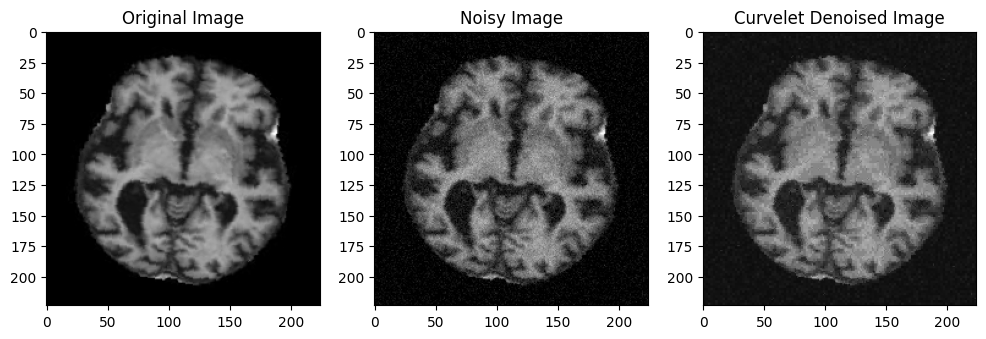

Processed 0/5121 images
Processed 100/5121 images
Processed 200/5121 images
Processed 300/5121 images
Processed 400/5121 images
Processed 500/5121 images
Processed 600/5121 images
Processed 700/5121 images
Processed 800/5121 images
Processed 900/5121 images
Processed 1000/5121 images
Processed 1100/5121 images
Processed 1200/5121 images
Processed 1300/5121 images
Processed 1400/5121 images
Processed 1500/5121 images
Processed 1600/5121 images
Processed 1700/5121 images
Processed 1800/5121 images
Processed 1900/5121 images
Processed 2000/5121 images
Processed 2100/5121 images
Processed 2200/5121 images
Processed 2300/5121 images
Processed 2400/5121 images
Processed 2500/5121 images
Processed 2600/5121 images
Processed 2700/5121 images
Processed 2800/5121 images
Processed 2900/5121 images
Processed 3000/5121 images
Processed 3100/5121 images
Processed 3200/5121 images
Processed 3300/5121 images
Processed 3400/5121 images
Processed 3500/5121 images
Processed 3600/5121 images
Processed 370

In [ ]:
# Loop through the data loader to apply denoising to each image
for i, (image, label) in enumerate(data_loader):
    # Convert the image from Tensor to NumPy array
    image_np = image.numpy().squeeze()  # Remove the extra batch dimension

    # Convert to grayscale (if it's a colored image)
    if image_np.shape[0] == 3:
        image_np = np.mean(image_np, axis=0)  # Convert to grayscale by averaging channels
    
    # Add noise to the image (Gaussian noise)
    noisy_image = util.random_noise(image_np, mode='gaussian', mean=0, var=0.01)

    # Denoise the image using Wavelet Transform
    denoised_image = denoising(noisy_image, wavelet='bior1.3', threshold_factor=0.1)


    # Convert the denoised images back to Tensor for further processing if needed
    denoised_image_tensor = torch.Tensor(denoised_image).unsqueeze(0)



    if i == 0:  # Visualize the first image as an example
        plt.figure(figsize=(12, 6))
        plt.subplot(1, 3, 1)
        plt.imshow(image_np, cmap='gray')
        plt.title("Original Image")
        
        plt.subplot(1, 3, 2)
        plt.imshow(noisy_image, cmap='gray')
        plt.title("Noisy Image")
        
        plt.subplot(1, 3, 3)
        plt.imshow(denoised_image, cmap='gray')
        plt.title("Curvelet Denoised Image")
        
        plt.show()
    #cv2.imwrite(f"{save_dir}/{data_fol[int(label)]}/denoised_image_{i+1}.png", denoised_image) 
    plt.imsave(f"{save_dir}/{data_fol[int(label)]}/denoised_image_{i+1}.png", denoised_image, cmap='gray')
    if i % 100 == 0:  # Print progress every 100 images
        print(f"Processed {i}/{len(dataset)} images")
print("transformation done!")

In [37]:
data_dir = "Alzheimer_sDataset"  # Provide the correct path to your dataset
dataset = datasets.ImageFolder(os.path.join(data_dir, 'test'), transform=transform)
data_loader = DataLoader(dataset, batch_size=1, shuffle=False)


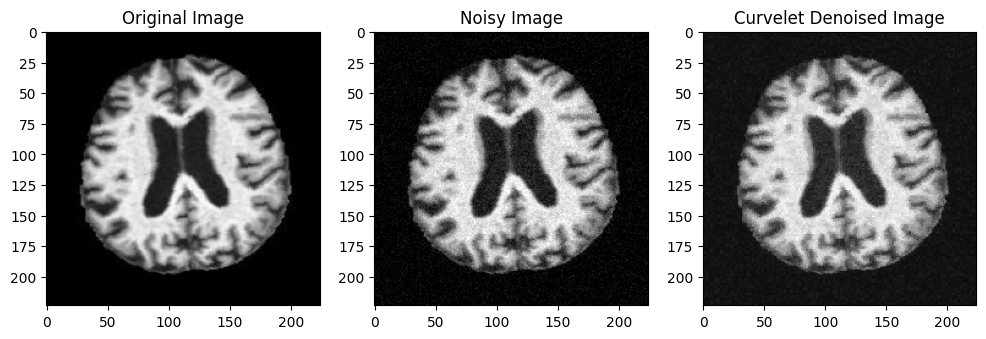

Processed 0/1279 images
Processed 100/1279 images
Processed 200/1279 images
Processed 300/1279 images
Processed 400/1279 images
Processed 500/1279 images
Processed 600/1279 images
Processed 700/1279 images
Processed 800/1279 images
Processed 900/1279 images
Processed 1000/1279 images
Processed 1100/1279 images
Processed 1200/1279 images
transformation done!


In [ ]:
for i, (image, label) in enumerate(data_loader):
    # Convert the image from Tensor to NumPy array
    image_np = image.numpy().squeeze()  # Remove the extra batch dimension

    # Convert to grayscale (if it's a colored image)
    if image_np.shape[0] == 3:
        image_np = np.mean(image_np, axis=0)  # Convert to grayscale by averaging channels
    
    # Add noise to the image (Gaussian noise)
    noisy_image = util.random_noise(image_np, mode='gaussian', mean=0, var=0.01)

    # Denoise the image using Wavelet Transform
    denoised_image = denoising(noisy_image, wavelet='bior1.3', threshold_factor=0.1)


    # Convert the denoised images back to Tensor for further processing if needed
    denoised_image_tensor = torch.Tensor(denoised_image).unsqueeze(0)



    if i == 0:  # Visualize the first image as an example
        plt.figure(figsize=(12, 6))
        plt.subplot(1, 3, 1)
        plt.imshow(image_np, cmap='gray')
        plt.title("Original Image")
        
        plt.subplot(1, 3, 2)
        plt.imshow(noisy_image, cmap='gray')
        plt.title("Noisy Image")
        
        plt.subplot(1, 3, 3)
        plt.imshow(denoised_image, cmap='gray')
        plt.title("Curvelet Denoised Image")
        
        plt.show()
    #cv2.imwrite(f"{save_dir}/{data_fol[int(label)]}/denoised_image_{i+1}.png", denoised_image) 
    plt.imsave(f"{save_dir}/{data_fol[int(label)]}/denoised_image_{i+5121+1}.png", denoised_image, cmap='gray')
    if i % 100 == 0:  # Print progress every 100 images
        print(f"Processed {i}/{len(dataset)} images")
print("transformation done!")

In [30]:
from skimage.metrics import structural_similarity as ssim
from math import log10, sqrt

Peak Signal-to-Noise Ratio (PSNR)

In [31]:
#PSNR measures the difference between the original and the denoised image. A higher PSNR indicates better quality, meaning the denoised image is closer to the original.
def psnr(image1, image2):
    mse = np.mean((image1 - image2) ** 2)
    if mse == 0:
        return 100  # No difference, perfect image
    return 10 * log10(255 * 255 / mse)

In [36]:
original_image = cv2.resize(cv2.imread( 'Alzheimer_sDataset/train/MildDemented/mildDem0.jpg',cv2.IMREAD_GRAYSCALE),(224, 224))
denoised_image = cv2.resize(cv2.imread('Transformed_Image/MildDemented/denoised_image_1.png', cv2.IMREAD_GRAYSCALE),(224, 224))

psnr_value = psnr(original_image, denoised_image)

print(f"PSNR: {psnr_value} dB")


PSNR: 27.634544112085276 dB
